# Team A10: When you fly matters more than who you fly with
**Questrom Chart Champ Datathon, 2025 BTS on-time data (all 6.4M flights)**

The brief asks for 2 to 4 defensible changes to a company's travel policy. This notebook does one thing:
it tests each proposed rule against a **kill test** we wrote down before running it. A rule that fails gets dropped.

| # | Rule | Kill test |
|---|---|---|
| 1 | Fly early | Does the morning advantage survive on the **same route and airline**? Is there a mechanism? |
| 2 | Night before (peak months) | Is the risk of a lost day (1h+ late or cancelled) clearly higher in peak-month evenings? |
| 3 | Size the buffer | Does a buffer set on one half of each month cover ~90% of delays in the other half? |
| 4 | Prefer the reliable carrier | Does a route's best carrier in Jan–Jun stay better in Jul–Dec? |

Run top to bottom. Every number in the deck comes from the `R` dictionary saved at the end.

In [1]:
# Setup: libraries, chart style, and where the data lives
import glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = 'data/full_2025/'   # folder with 2025_01.csv.gz ... 2025_12.csv.gz
IMG = 'images/notebook_output/'                                                            # charts are saved here for the deck
import os; os.makedirs(IMG, exist_ok=True)

GREEN, ORANGE, GREY, INK = '#0F3D2E', '#C8501E', '#B8C2BC', '#17211C'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 14, 'axes.edgecolor': '#888'})
R = {}   # every result we quote goes in here
def save(name):
    plt.tight_layout(); plt.savefig(IMG + name + '.png', dpi=200, bbox_inches='tight'); plt.show()

## 1. Load the data
We only read the columns we use. That keeps 6.4 million rows small enough for a laptop.

In [2]:
cols = ['MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'ORIGIN_STATE_ABR', 'TAIL_NUM', 'DEP_DELAY', 'DISTANCE', 'CANCELLATION_CODE', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'ARR_DELAY',
        'CANCELLED', 'DIVERTED', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
files = sorted(glob.glob(DATA + '2025_*.csv.gz'))
df = pd.concat([pd.read_csv(f, usecols=cols, dtype={'OP_UNIQUE_CARRIER': 'category', 'ORIGIN': 'category',
                                                     'DEST': 'category', 'ORIGIN_STATE_ABR': 'category', 'TAIL_NUM': str, 'CANCELLATION_CODE': str}) for f in files], ignore_index=True)
# shrink memory: small number types are plenty here
for c in ['TAIL_NUM', 'CANCELLATION_CODE', 'OP_UNIQUE_CARRIER', 'ORIGIN', 'DEST', 'ORIGIN_STATE_ABR']:
    df[c] = df[c].astype(str).astype('category')
for c in ['DEP_DELAY', 'DISTANCE', 'ARR_DELAY', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']:
    df[c] = df[c].astype('float32')
for c in ['MONTH', 'DAY_OF_MONTH']:
    df[c] = df[c].astype('int8')
print(f'{len(df):,} flights from {len(files)} monthly files')

6,398,056 flights from 12 monthly files


## 2. Definitions (kept simple on purpose)
- **Late** = landed 15+ minutes after schedule (the BTS industry standard), among flights that flew.
- **Severe** = cancelled, diverted, or 1+ hour late: the kind of delay that loses the meeting.
- **Time bands** by scheduled departure: Morning 5–10 am, Evening 5–8 pm.
- **Cost per flight** = lost hours × value of time. Late flights: minutes late (capped at 3 h). Cancellations: 4 h. Default $60/h, tested later.

In [3]:
df['hour'] = (df.CRS_DEP_TIME // 100).clip(upper=23)
df['cancelled'] = df.CANCELLED == 1
df['diverted'] = df.DIVERTED == 1
df['flew'] = ~df.cancelled & ~df.diverted & df.ARR_DELAY.notna()
df['late'] = df.flew & (df.ARR_DELAY >= 15)
df['disrupted'] = df.cancelled | df.diverted | df.late
df['severe'] = df.cancelled | df.diverted | (df.flew & (df.ARR_DELAY >= 60))
df['band'] = np.select([df.hour.between(5, 9), df.hour.between(17, 19)], ['Morning', 'Evening'], 'Other')

def lost_hours(d):
    late_h = d.ARR_DELAY.clip(upper=180).where(d.late, 0).fillna(0) / 60
    return late_h + d.cancelled * 4
df['lost_h'] = lost_hours(df)
VOT = 60
def late_rate(d):  # late flights / flights that flew, in %
    return d.late.sum() / d.flew.sum() * 100

## 3. The problem in three numbers

In [4]:
R['n_flights'] = len(df)
R['disrupted_pct'] = df.disrupted.mean() * 100
R['late_pct'] = late_rate(df)
R['cancel_pct'] = df.cancelled.mean() * 100
R['cost_per_flight'] = df.lost_h.mean() * VOT
print(f"Disrupted: {R['disrupted_pct']:.1f}%  |  Late (of flights that flew): {R['late_pct']:.1f}%  |  "
      f"Cancelled: {R['cancel_pct']:.2f}%  |  Cost: ${R['cost_per_flight']:.2f} per flight at ${VOT}/h")

Disrupted: 23.5%  |  Late (of flights that flew): 22.2%  |  Cancelled: 1.49%  |  Cost: $17.06 per flight at $60/h


## 4. The insight: risk climbs through the day
Late rate by scheduled departure hour. Bars are coloured by the two bands we compare.

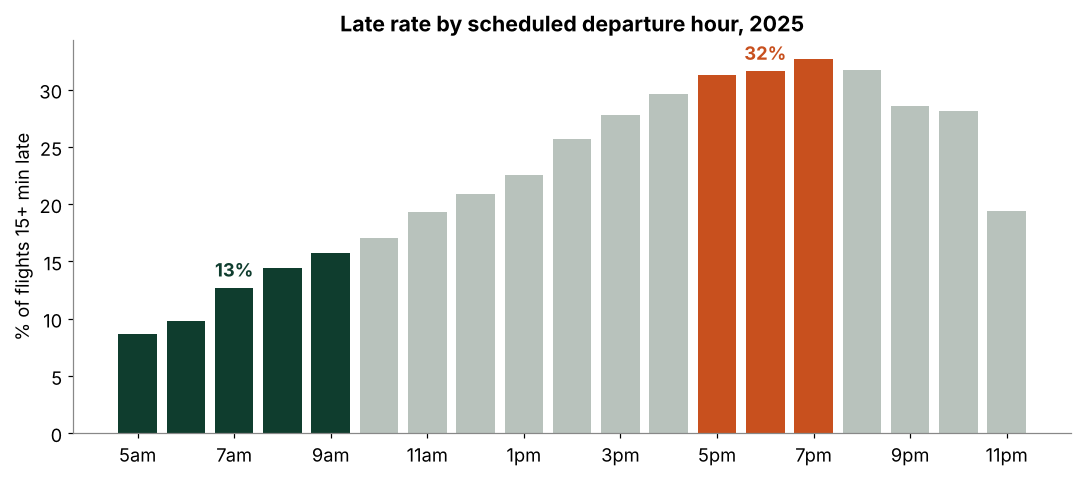

Morning 12.6% vs Evening 31.8%  (gap 19.2 pts)


In [5]:
g = df[df.hour >= 5].groupby('hour')
by_hour = (g.late.sum() / g.flew.sum() * 100)
R['late_by_hour'] = by_hour.round(1).to_dict()
R['late_morning'] = late_rate(df[df.band == 'Morning'])
R['late_evening'] = late_rate(df[df.band == 'Evening'])
R['raw_gap_pp'] = R['late_evening'] - R['late_morning']

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [GREEN if 5 <= h <= 9 else ORANGE if 17 <= h <= 19 else GREY for h in by_hour.index]
ax.bar(by_hour.index, by_hour.values, color=colors)
ax.set_xticks(range(5, 24, 2)); ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in range(5, 24, 2)])
ax.set_ylabel('% of flights 15+ min late'); ax.set_title('Late rate by scheduled departure hour, 2025')
for h, c in [(7, GREEN), (18, ORANGE)]:
    ax.text(h, by_hour[h] + 1, f'{by_hour[h]:.0f}%', ha='center', color=c, fontweight='bold')
save('01_late_by_hour')
print(f"Morning {R['late_morning']:.1f}% vs Evening {R['late_evening']:.1f}%  (gap {R['raw_gap_pp']:.1f} pts)")

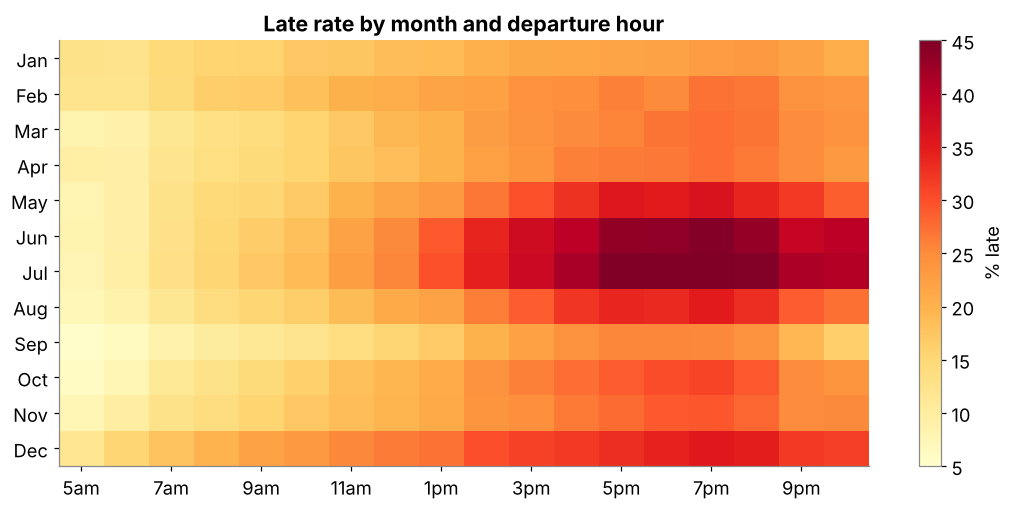

Jun-Jul evenings 44.8% late vs Sep mornings 8.8%  (5.1x)


In [6]:
# Same picture by month: where is the evening problem worst?
hm = df[df.hour.between(5, 22)].groupby(['MONTH', 'hour']).apply(late_rate, include_groups=False).unstack()
fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(hm.values, cmap='YlOrRd', aspect='auto', vmin=5, vmax=45)
ax.set_yticks(range(12)); ax.set_yticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_xticks(range(0, 18, 2)); ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in range(5, 23, 2)])
plt.colorbar(im, ax=ax, label='% late'); ax.set_title('Late rate by month and departure hour')
save('02_heatmap')
hot = df[df.MONTH.isin([6, 7]) & (df.band == 'Evening')]; calm = df[(df.MONTH == 9) & (df.band == 'Morning')]
R['hot_late'], R['calm_late'] = late_rate(hot), late_rate(calm)
print(f"Jun-Jul evenings {R['hot_late']:.1f}% late vs Sep mornings {R['calm_late']:.1f}%  ({R['hot_late']/R['calm_late']:.1f}x)")

## 5. Kill test 1a: is it the hour, or just different routes?
Evening flights might simply be on worse routes or airlines. So we compare morning vs evening **inside the same
route and the same airline** (e.g. Delta BOS→ATL at 7 am vs Delta BOS→ATL at 6 pm), then average across all such pairs.

**Rule 1 survives if** the matched gap stays large (we set the bar at least half the raw gap).

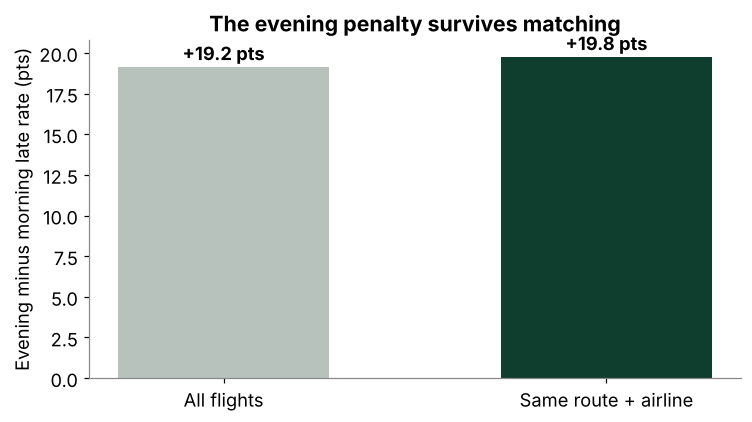

3,918 route-airline pairs (81% of morning+evening flights)
Raw gap 19.2 pts -> matched gap 19.8 pts; evening worse in 97% of pairs. PASS = True
Matched cost saving per trip moved evening->morning: $13.92


In [7]:
fl = df[df.flew & df.band.isin(['Morning', 'Evening'])]
grp = fl.groupby(['ORIGIN', 'DEST', 'OP_UNIQUE_CARRIER', 'band'], observed=True).agg(n=('late', 'size'), late=('late', 'mean'),
                                                                                    cost=('lost_h', 'mean'))
wide = grp.unstack('band').dropna()
wide = wide[(wide[('n', 'Morning')] >= 30) & (wide[('n', 'Evening')] >= 30)]   # enough flights in both bands
w = wide[('n', 'Morning')] + wide[('n', 'Evening')]
gap = (wide[('late', 'Evening')] - wide[('late', 'Morning')]) * 100
R['matched_pairs'] = len(wide)
R['matched_share_flights'] = w.sum() / len(fl) * 100
R['matched_gap_pp'] = np.average(gap, weights=w)
R['matched_share_evening_worse'] = (gap > 0).mean() * 100
R['matched_cost_saving'] = np.average((wide[('cost', 'Evening')] - wide[('cost', 'Morning')]) * VOT, weights=w)
R['test1a_pass'] = bool(R['matched_gap_pp'] >= 0.5 * R['raw_gap_pp'])

fig, ax = plt.subplots(figsize=(7, 4))
vals = [R['raw_gap_pp'], R['matched_gap_pp']]
ax.bar(['All flights', 'Same route + airline'], vals, color=[GREY, GREEN], width=0.55)
for i, v in enumerate(vals): ax.text(i, v + 0.4, f'+{v:.1f} pts', ha='center', fontweight='bold')
ax.set_ylabel('Evening minus morning late rate (pts)'); ax.set_title('The evening penalty survives matching')
save('03_matched_gap')
print(f"{R['matched_pairs']:,} route-airline pairs ({R['matched_share_flights']:.0f}% of morning+evening flights)")
print(f"Raw gap {R['raw_gap_pp']:.1f} pts -> matched gap {R['matched_gap_pp']:.1f} pts; "
      f"evening worse in {R['matched_share_evening_worse']:.0f}% of pairs. PASS = {R['test1a_pass']}")
print(f"Matched cost saving per trip moved evening->morning: ${R['matched_cost_saving']:.2f}")

In [8]:
# Robustness: does the gap depend on where we draw 'late'?
rob = {}
for cut in [15, 30, 60]:
    m = df[df.flew & (df.band == 'Morning')]; e = df[df.flew & (df.band == 'Evening')]
    rob[cut] = ((e.ARR_DELAY >= cut).mean() * 100, (m.ARR_DELAY >= cut).mean() * 100)
R['robust'] = {k: {'evening': v[0], 'morning': v[1], 'ratio': v[0] / v[1]} for k, v in rob.items()}
pd.DataFrame(R['robust']).T.round(1)

,evening,morning,ratio
15,31.8,12.6,2.5
30,22.4,7.5,3.0
60,12.8,4.0,3.2


## 6. Kill test 1b: why? Delays stack up through the day
BTS splits each late flight's minutes by cause. If **late-arriving aircraft** minutes grow through the day,
that's the mechanism: an early delay rides the same plane into every later flight.

**Survives if** late-aircraft minutes per flight rise from morning to evening and are the biggest evening cause.

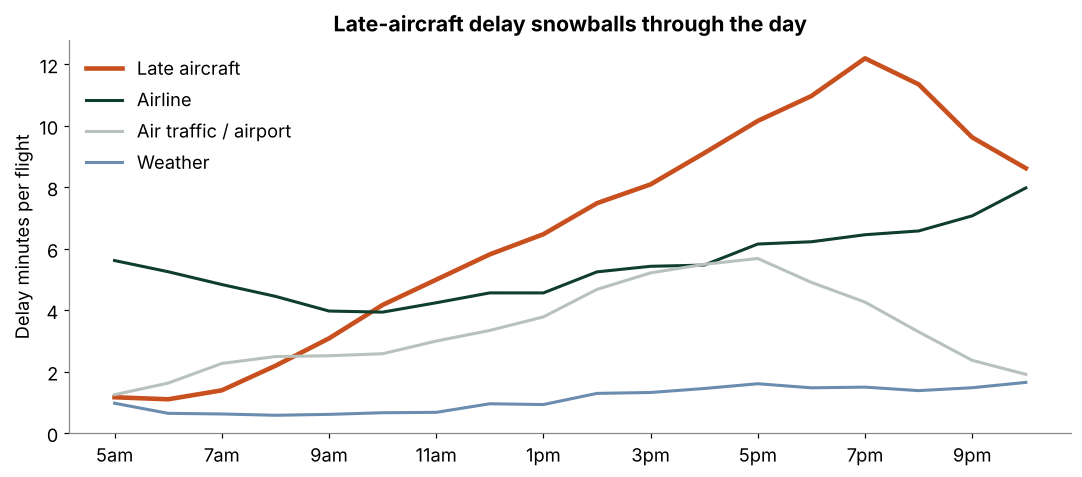

Late-aircraft minutes per flight: morning 1.8 -> evening 11.1; 46% of evening delay minutes (weather 6%). PASS = True


In [9]:
causes = {'LATE_AIRCRAFT_DELAY': 'Late aircraft', 'CARRIER_DELAY': 'Airline', 'NAS_DELAY': 'Air traffic / airport',
          'WEATHER_DELAY': 'Weather'}
f = df.loc[df.flew & df.hour.between(5, 22), list(causes) + ['hour', 'band']]
mins = f.groupby('hour')[list(causes)].apply(lambda d: d.fillna(0).mean()).rename(columns=causes)
fig, ax = plt.subplots(figsize=(10, 4.5))
for c, col in zip(mins.columns, [ORANGE, GREEN, GREY, '#6A8CAF']):
    ax.plot(mins.index, mins[c], lw=3 if c == 'Late aircraft' else 2, color=col, label=c)
ax.set_xticks(range(5, 23, 2)); ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in range(5, 23, 2)])
ax.set_ylabel('Delay minutes per flight'); ax.set_title('Late-aircraft delay snowballs through the day'); ax.legend(frameon=False)
save('04_causes_by_hour')
ev = f[f.band == 'Evening'][list(causes)].fillna(0).mean(); mo = f[f.band == 'Morning'][list(causes)].fillna(0).mean()
R['la_min_morning'], R['la_min_evening'] = mo['LATE_AIRCRAFT_DELAY'], ev['LATE_AIRCRAFT_DELAY']
R['la_share_evening'] = ev['LATE_AIRCRAFT_DELAY'] / ev.sum() * 100
R['weather_share_evening'] = ev['WEATHER_DELAY'] / ev.sum() * 100
R['test1b_pass'] = bool(R['la_min_evening'] > 2 * R['la_min_morning'] and ev.idxmax() == 'LATE_AIRCRAFT_DELAY')
print(f"Late-aircraft minutes per flight: morning {R['la_min_morning']:.1f} -> evening {R['la_min_evening']:.1f}; "
      f"{R['la_share_evening']:.0f}% of evening delay minutes (weather {R['weather_share_evening']:.0f}%). PASS = {R['test1b_pass']}")

## 7. Kill test 2: when is a lost day likely enough to fly in the night before?
**Severe** = cancelled, diverted or 1+ hour late. **Survives if** peak-month evenings are clearly above the
yearly average (we set the bar at 1.5x).

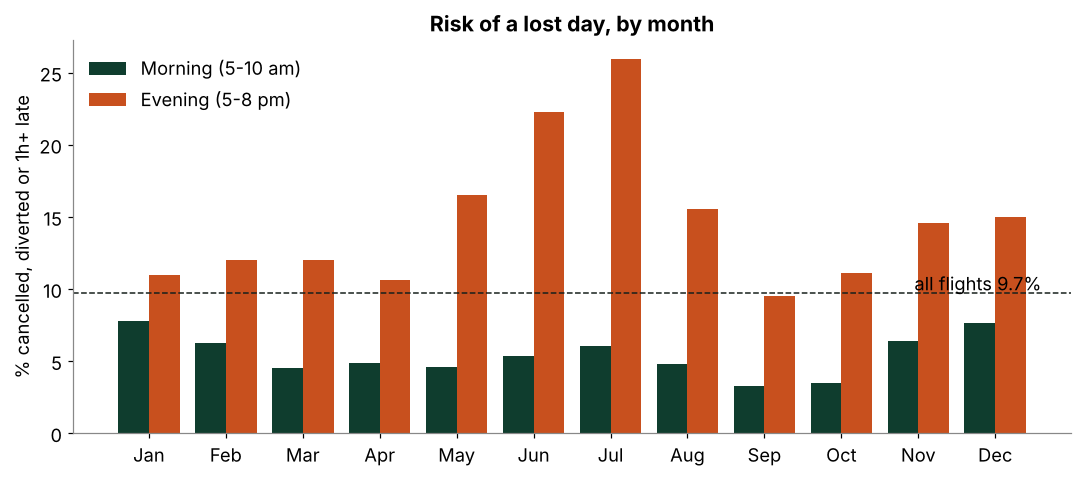

Peak months [7, 6, 5]: evening severe 21.6% vs morning 5.3% vs all 9.7%. PASS = True


In [10]:
sev = df[df.band.isin(['Morning', 'Evening'])].groupby(['MONTH', 'band']).severe.mean().unstack() * 100
R['severe_all'] = df.severe.mean() * 100
R['severe_by_month_evening'] = sev['Evening'].round(2).to_dict()
R['severe_by_month_morning'] = sev['Morning'].round(2).to_dict()
peak = sev['Evening'].sort_values(ascending=False).head(3)
R['peak_months'] = [int(m) for m in peak.index]
R['severe_peak_evening'] = df[df.MONTH.isin(R['peak_months']) & (df.band == 'Evening')].severe.mean() * 100
R['severe_peak_morning'] = df[df.MONTH.isin(R['peak_months']) & (df.band == 'Morning')].severe.mean() * 100
R['test2_pass'] = bool(R['severe_peak_evening'] >= 1.5 * R['severe_all'])
# same lines at the other two cutoffs, for the comparison chart
df['severe120'] = df.cancelled | df.diverted | (df.flew & (df.ARR_DELAY >= 120))
for tag, col in [('15', 'disrupted'), ('120', 'severe120')]:
    t = df[df.band.isin(['Morning', 'Evening'])].groupby(['MONTH', 'band'])[col].mean().unstack() * 100
    R[f'cut{tag}_by_month_evening'] = t['Evening'].round(2).to_dict()
    R[f'cut{tag}_by_month_morning'] = t['Morning'].round(2).to_dict()
    R[f'cut{tag}_peak_evening'] = df[df.MONTH.isin(R['peak_months']) & (df.band == 'Evening')][col].mean() * 100
    R[f'cut{tag}_all'] = df[col].mean() * 100

M = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(12)
ax.bar(x - 0.2, sev['Morning'], 0.4, color=GREEN, label='Morning (5-10 am)')
ax.bar(x + 0.2, sev['Evening'], 0.4, color=ORANGE, label='Evening (5-8 pm)')
ax.axhline(R['severe_all'], color=INK, ls='--', lw=1); ax.text(11.6, R['severe_all'] + 0.2, f"all flights {R['severe_all']:.1f}%", ha='right')
ax.set_xticks(x); ax.set_xticklabels(M); ax.set_ylabel('% cancelled, diverted or 1h+ late')
ax.set_title('Risk of a lost day, by month'); ax.legend(frameon=False, loc='upper left')
save('05_severe_by_month')
print(f"Peak months {R['peak_months']}: evening severe {R['severe_peak_evening']:.1f}% vs morning {R['severe_peak_morning']:.1f}% "
      f"vs all {R['severe_all']:.1f}%. PASS = {R['test2_pass']}")

In [11]:
# Rule 2 break-even: fly in the night before when  P(lost day) x meeting value > hotel cost
HOTEL = 200
p = R['severe_peak_evening'] / 100
R['hotel'] = HOTEL
R['breakeven_meeting_value'] = HOTEL / p
print(f"At {p:.1%} risk, a ${HOTEL} hotel pays off when the meeting is worth more than ${R['breakeven_meeting_value']:,.0f}")

At 21.6% risk, a $200 hotel pays off when the meeting is worth more than $927


## 8. Kill test 3: a buffer that covers 9 in 10 delays
We set the buffer (90th percentile of arrival delay) for each month and time band using **days 1–15**,
then check how often it actually covered delays on **days 16–31**, which it never saw.

**Survives if** test coverage averages 87–93%.

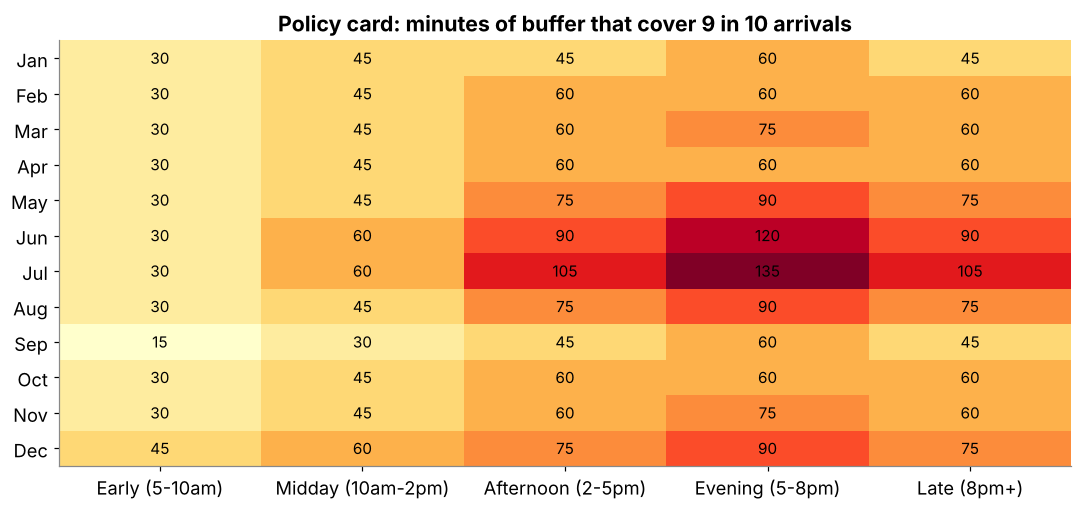

Coverage on unseen days: mean 90.4% (range 85.3-94.5%). PASS = True


In [12]:
bands = {'Early (5-10am)': (5, 9), 'Midday (10am-2pm)': (10, 13), 'Afternoon (2-5pm)': (14, 16),
         'Evening (5-8pm)': (17, 19), 'Late (8pm+)': (20, 23)}
f = df.loc[df.flew, ['MONTH', 'DAY_OF_MONTH', 'hour', 'ARR_DELAY']].copy()   # only the columns we need
f['tband'] = pd.cut(f.hour, [4, 9, 13, 16, 19, 23], labels=list(bands))
train, test = f[f.DAY_OF_MONTH <= 15], f[f.DAY_OF_MONTH > 15]
p90 = train.groupby(['MONTH', 'tband'], observed=True).ARR_DELAY.quantile(0.9)
t = test.join(p90.rename('buf'), on=['MONTH', 'tband'])
cov = (t.ARR_DELAY <= t.buf).groupby([t.MONTH, t.tband], observed=True).mean() * 100
R['buffer_cov_mean'], R['buffer_cov_min'], R['buffer_cov_max'] = cov.mean(), cov.min(), cov.max()
R['test3_pass'] = bool(87 <= R['buffer_cov_mean'] <= 93)

# The policy card: buffer in minutes, rounded UP to 15, computed on the full year
card = f.groupby(['MONTH', 'tband'], observed=True).ARR_DELAY.quantile(0.9).unstack()
card = (np.ceil(card.clip(lower=0) / 15) * 15).astype(int); card.index = M
R['buffer_card'] = card.to_dict()
R['buffer_typical_morning'] = int(card['Early (5-10am)'].median()); R['buffer_typical_evening'] = int(card['Evening (5-8pm)'].median())
R['buffer_max'] = int(card.values.max())

fig, ax = plt.subplots(figsize=(10, 4.8))
im = ax.imshow(card.values, cmap='YlOrRd', aspect='auto')
for i in range(card.shape[0]):
    for j in range(card.shape[1]):
        ax.text(j, i, card.values[i, j], ha='center', va='center', fontsize=10)
ax.set_xticks(range(5)); ax.set_xticklabels(list(bands)); ax.set_yticks(range(12)); ax.set_yticklabels(M)
ax.set_title('Policy card: minutes of buffer that cover 9 in 10 arrivals')
save('06_buffer_card')
print(f"Coverage on unseen days: mean {R['buffer_cov_mean']:.1f}% (range {R['buffer_cov_min']:.1f}-{R['buffer_cov_max']:.1f}%). PASS = {R['test3_pass']}")

## 9. Kill test 4: do 'reliable carriers' stay reliable?
On each busy route served by 2+ airlines, find the airline with the lowest late rate in **Jan–Jun**.
Then check if it still beats the other airlines on that route in **Jul–Dec**.

**Survives if** the Jan–Jun winner still beats the others on at least 70% of routes (a coin flip would be 50%).

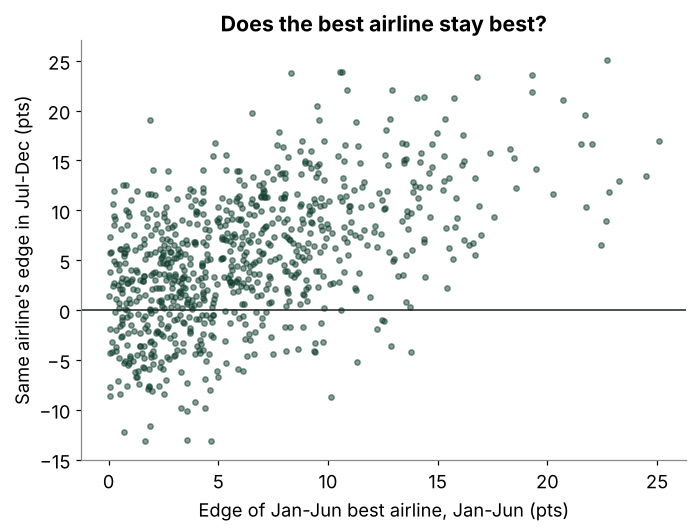

793 routes. Jan-Jun winner still better in Jul-Dec on 77% of routes. Edge shrinks from 6.3 to 5.1 pts. PASS = True


In [13]:
f = df.loc[df.flew, ['ORIGIN', 'DEST', 'OP_UNIQUE_CARRIER', 'MONTH', 'late']].copy(); f['half'] = np.where(f.MONTH <= 6, 'H1', 'H2')
rc = f.groupby(['ORIGIN', 'DEST', 'OP_UNIQUE_CARRIER', 'half'], observed=True).agg(n=('late', 'size'), late=('late', 'mean')).unstack('half').dropna()
rc = rc[(rc[('n', 'H1')] >= 200) & (rc[('n', 'H2')] >= 200)].reset_index()
rc.columns = ['ORIGIN', 'DEST', 'carrier', 'n1', 'n2', 'late1', 'late2']
rc = rc[rc.groupby(['ORIGIN', 'DEST']).carrier.transform('size') >= 2]
rows = []
for (o, d), g in rc.groupby(['ORIGIN', 'DEST']):
    best = g.loc[g.late1.idxmin()]; others = g[g.carrier != best.carrier]
    others_h2 = np.average(others.late2, weights=others.n2)
    rows.append({'route': f'{o}-{d}', 'flights': g.n1.sum() + g.n2.sum(), 'h1_edge': (np.average(others.late1, weights=others.n1) - best.late1) * 100,
                 'h2_edge': (others_h2 - best.late2) * 100})
routes = pd.DataFrame(rows)
R['carrier_routes'] = len(routes)
R['carrier_hold_pct'] = (routes.h2_edge > 0).mean() * 100
R['carrier_edge_h1'] = np.average(routes.h1_edge, weights=routes.flights)
R['carrier_edge_h2'] = np.average(routes.h2_edge, weights=routes.flights)
R['test4_pass'] = bool(R['carrier_hold_pct'] >= 70)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(routes.h1_edge, routes.h2_edge, s=12, alpha=0.5, color=GREEN)
ax.axhline(0, color=INK, lw=1); ax.set_xlabel('Edge of Jan-Jun best airline, Jan-Jun (pts)')
ax.set_ylabel('Same airline\'s edge in Jul-Dec (pts)'); ax.set_title('Does the best airline stay best?')
save('07_carrier_persistence')
print(f"{R['carrier_routes']} routes. Jan-Jun winner still better in Jul-Dec on {R['carrier_hold_pct']:.0f}% of routes. "
      f"Edge shrinks from {R['carrier_edge_h1']:.1f} to {R['carrier_edge_h2']:.1f} pts. PASS = {R['test4_pass']}")

## 10. What it's worth, and what if our $60/hour is wrong?
The saving per trip moved from evening to morning uses the **matched** comparison (same route and airline), so it isn't inflated by route mix.

In [14]:
R['cost_morning'] = df[df.band == 'Morning'].lost_h.mean() * VOT
R['cost_evening'] = df[df.band == 'Evening'].lost_h.mean() * VOT
R['vot_sweep'] = {v: {'per_flight': df.lost_h.mean() * v, 'saving_per_moved_trip': R['matched_cost_saving'] / VOT * v} for v in [30, 60, 100, 150]}
R['share_evening_flights'] = (df.band == 'Evening').mean() * 100
pd.DataFrame(R['vot_sweep']).T.round(2).rename_axis('$ per hour')

,per_flight,saving_per_moved_trip
$ per hour,,
30,8.53,6.96
60,17.06,13.92
100,28.43,23.20
150,42.64,34.80


## 10b. Every other factor in the data: does any of them change the rules?
A buyer will ask "why only the hour?". So we scan every factor this table can measure, in four groups:

| Group | Factors |
|---|---|
| **Time** | hour of day, day of week, month, season, holiday weeks |
| **Place** | US region of the departure airport, hub size (busiest 30 airports vs the rest) |
| **Flight** | airline, distance, which leg of the plane's day it is, time made up in the air |
| **Weather & cancellations** | weather share of delay minutes by region and season, causes of cancellations |

For each one we ask two questions: **how much does it move the late rate?** and **does the evening penalty still hold inside it?**

**Can't test here:** El Niño / La Niña and other multi-year climate cycles (needs several years of data plus NOAA records),
fares, connections and trip purpose (not in BTS).

In [15]:
# --- Build the extra factor columns ---
REGION = {**{s: 'Northeast' for s in 'CT ME MA NH RI VT NJ NY PA'.split()},
          **{s: 'Midwest' for s in 'IL IN MI OH WI IA KS MN MO NE ND SD'.split()},
          **{s: 'South' for s in 'DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX'.split()},
          **{s: 'West' for s in 'AZ CO ID MT NV NM UT WY AK CA HI OR WA'.split()}}
df['region'] = df.ORIGIN_STATE_ABR.astype(str).map(REGION).fillna('Territories')
df['season'] = df.MONTH.map({12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
                             6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Fall', 10: 'Fall', 11: 'Fall'})
md_ = df.MONTH.astype(int) * 100 + df.DAY_OF_MONTH.astype(int)          # e.g. 1125 = Nov 25
df['holiday'] = np.where(md_.between(1122, 1130) | (md_ >= 1220) | (md_ <= 103) | md_.between(701, 707) | md_.between(523, 527) | md_.between(829, 902),
                         'Holiday week', 'Normal week')
top30 = df.ORIGIN.value_counts().head(30).index
df['hub'] = np.where(df.ORIGIN.isin(top30), 'Top-30 hub', 'Other airport')
df['dist_band'] = pd.cut(df.DISTANCE, [0, 500, 1000, 2000, 6000], labels=['<500 mi', '500-1,000 mi', '1,000-2,000 mi', '2,000+ mi'])
# Which leg of the plane's day is this flight? (same tail number, same date, ordered by scheduled departure)
df['leg'] = df.groupby(['TAIL_NUM', 'MONTH', 'DAY_OF_MONTH'], observed=True).CRS_DEP_TIME.rank(method='first')
df['leg_band'] = pd.cut(df.leg, [0, 1, 2, 3, 4, 99], labels=['1st', '2nd', '3rd', '4th', '5th+'])
DOW = {1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat', 7: 'Sun'}
df['dow'] = df.DAY_OF_WEEK.map(DOW)
for c in ['region', 'season', 'holiday', 'hub', 'dow', 'band']:
    df[c] = df[c].astype('category')   # saves memory
print('factor columns ready')

factor columns ready


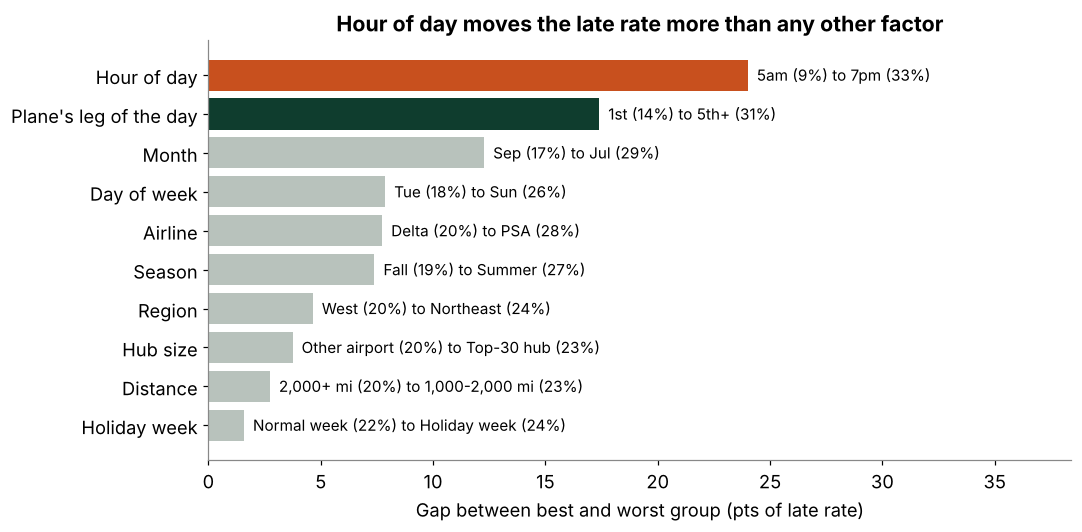

,group,factor,best,worst,spread_pts,cost_spread_$
0,Time,Hour of day,5am (9%),7pm (33%),24.0,16.6
9,Flight,Plane's leg of the day,1st (14%),5th+ (31%),17.4,15.4
1,Time,Month,Sep (17%),Jul (29%),12.3,14.5
3,Time,Day of week,Tue (18%),Sun (26%),7.9,7.0
7,Flight,Airline,Delta (20%),PSA (28%),7.7,16.3
2,Time,Season,Fall (19%),Summer (27%),7.4,7.3
5,Place,Region,West (20%),Northeast (24%),4.6,7.9
6,Place,Hub size,Other airport (20%),Top-30 hub (23%),3.7,1.5
8,Flight,Distance,"2,000+ mi (20%)","1,000-2,000 mi (23%)",2.7,4.0
4,Time,Holiday week,Normal week (22%),Holiday week (24%),1.6,1.2


In [16]:
# --- How much does each factor move the late rate? ---
FACTORS = [('Time', 'Hour of day', 'hour'), ('Time', 'Month', 'MONTH'), ('Time', 'Season', 'season'),
           ('Time', 'Day of week', 'dow'), ('Time', 'Holiday week', 'holiday'),
           ('Place', 'Region', 'region'), ('Place', 'Hub size', 'hub'),
           ('Flight', 'Airline', 'OP_UNIQUE_CARRIER'), ('Flight', 'Distance', 'dist_band'), ('Flight', "Plane's leg of the day", 'leg_band')]
MON = dict(enumerate(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], 1))
AIR = {'AA': 'American', 'DL': 'Delta', 'UA': 'United', 'WN': 'Southwest', 'AS': 'Alaska', 'B6': 'JetBlue', 'NK': 'Spirit',
       'F9': 'Frontier', 'G4': 'Allegiant', 'HA': 'Hawaiian', 'MQ': 'Envoy', 'OH': 'PSA', 'OO': 'SkyWest', 'YX': 'Republic', '9E': 'Endeavor'}
def pretty(col, v):   # readable labels for charts: 19 -> 7pm, 7 -> Jul, DL -> Delta
    if col == 'hour': return f'{int(v) % 12 or 12}{"am" if int(v) < 12 else "pm"}'
    if col == 'MONTH': return MON[int(v)]
    if col == 'OP_UNIQUE_CARRIER': return AIR.get(str(v), str(v))
    return str(v)
rows, detail = [], {}
for grp, name, col in FACTORS:
    d = df[df.hour >= 5] if col == 'hour' else df
    g = d.groupby(col, observed=True); n = g.flew.sum(); r = (g.late.sum() / n * 100)[n > 50000]
    c = (g.lost_h.mean() * VOT)[n > 50000]
    detail[name] = pd.DataFrame({'late %': r.round(1), 'cost $': c.round(2)})
    rows.append({'group': grp, 'factor': name, 'best': f'{pretty(col, r.idxmin())} ({r.min():.0f}%)', 'worst': f'{pretty(col, r.idxmax())} ({r.max():.0f}%)',
                 'spread_pts': r.max() - r.min(), 'cost_spread_$': c.max() - c.min()})
scan = pd.DataFrame(rows).sort_values('spread_pts', ascending=False)
R['factor_scan'] = scan.round(2).to_dict(orient='records')
R['factor_detail'] = {k: {str(i): r.to_dict() for i, r in v.iterrows()} for k, v in detail.items()}

fig, ax = plt.subplots(figsize=(10, 5))
sc = scan.iloc[::-1]
ax.barh(sc.factor, sc.spread_pts, color=[ORANGE if f == 'Hour of day' else GREEN if f == "Plane's leg of the day" else GREY for f in sc.factor])
for i, (b, w, sp) in enumerate(sc[['best', 'worst', 'spread_pts']].values):
    ax.text(sp + 0.4, i, f'{b} to {w}', va='center', fontsize=10)
ax.set_xlabel('Gap between best and worst group (pts of late rate)'); ax.set_xlim(0, scan.spread_pts.max() * 1.6)
ax.set_title('Hour of day moves the late rate more than any other factor')
save('08_factor_scan')
scan.round(1)

In [17]:
# --- Does the evening penalty hold INSIDE every factor? (evening late rate / morning late rate per group) ---
f = df[df.flew & df.band.isin(['Morning', 'Evening'])]
hold = []
for grp, name, col in FACTORS:
    if col in ('hour', 'leg_band'): continue      # hour defines the bands; leg is the mechanism itself
    t = f.groupby([col, 'band'], observed=True).late.agg(['mean', 'size']).unstack()
    t = t[(t[('size', 'Morning')] > 5000) & (t[('size', 'Evening')] > 5000)]
    ratio = t[('mean', 'Evening')] / t[('mean', 'Morning')]
    hold.append({'factor': name, 'groups': len(ratio), 'lowest ratio': ratio.min(), 'in group': pretty(col, ratio.idxmin()), 'highest ratio': ratio.max()})
hold = pd.DataFrame(hold).sort_values('lowest ratio')
R['penalty_holds'] = hold.round(2).to_dict(orient='records')
R['penalty_min_ratio'] = float(hold['lowest ratio'].min())
print(f"Lowest evening/morning ratio in ANY group of ANY factor: {R['penalty_min_ratio']:.2f}x")
hold.round(2)

Lowest evening/morning ratio in ANY group of ANY factor: 1.54x


,factor,groups,lowest ratio,in group,highest ratio
0,Month,12,1.54,Jan,3.53
6,Airline,10,1.65,Alaska,3.84
1,Season,4,1.75,Winter,3.30
7,Distance,4,1.96,"2,000+ mi",2.62
2,Day of week,7,2.09,Sat,2.91
4,Region,5,2.26,Midwest,2.99
3,Holiday week,2,2.43,Holiday week,2.53
5,Hub size,2,2.47,Top-30 hub,2.55


In [18]:
# --- The plane's day: direct test of the snowball ---
lg = df[df.flew].groupby('leg_band', observed=True)
R['late_by_leg'] = (lg.late.sum() / lg.flew.sum() * 100).round(1).to_dict()
R['late_by_leg'] = {str(k): v for k, v in R['late_by_leg'].items()}
# Time made up in the air: arrival delay minus departure delay, for flights that left 15+ min late
dl = df[df.flew & (df.DEP_DELAY >= 15)]
R['made_up_min'] = float((dl.DEP_DELAY - dl.ARR_DELAY).median())
R['late_dep_still_late_pct'] = float((dl.ARR_DELAY >= 15).mean() * 100)
print('Late rate by leg of the plane day:', R['late_by_leg'])
print(f"Flights that left 15+ min late: median {R['made_up_min']:.0f} min made up in the air; {R['late_dep_still_late_pct']:.0f}% still arrive late")

Late rate by leg of the plane day: {'1st': 13.9, '2nd': 19.4, '3rd': 23.6, '4th': 27.6, '5th+': 31.3}
Flights that left 15+ min late: median 7 min made up in the air; 81% still arrive late


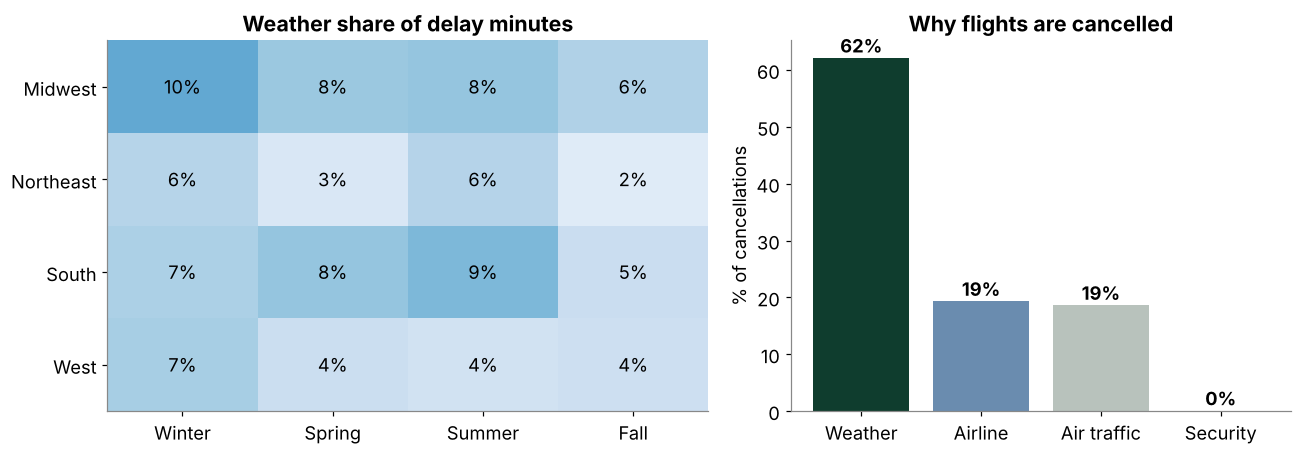

Weather = 6.5% of delay minutes. Cancellation causes: {'Weather': 62.1, 'Airline': 19.3, 'Air traffic': 18.6, 'Security': 0.1}. Worst month for cancellations: 1 (3.1%)


season,Winter,Spring,Summer,Fall
region,,,,
Midwest,10.5,7.7,8.0,6.3
Northeast,6.0,3.0,6.0,2.4
South,6.6,8.0,9.1,4.5
West,6.9,4.4,3.9,4.2


In [19]:
# --- Weather: where and when, and what cancels flights ---
cause_cols = ['LATE_AIRCRAFT_DELAY', 'CARRIER_DELAY', 'NAS_DELAY', 'WEATHER_DELAY', 'SECURITY_DELAY']
w = df[df.flew & (df.region != 'Territories')]
ws = w.groupby(['region', 'season'])[cause_cols].sum()
wshare = (ws.WEATHER_DELAY / ws.sum(axis=1) * 100).unstack()[['Winter', 'Spring', 'Summer', 'Fall']]
R['weather_share_all'] = float(w.WEATHER_DELAY.sum() / w[cause_cols].sum().sum() * 100)
R['weather_share_region_season'] = wshare.round(1).to_dict(orient='index')
cc = df[df.cancelled].CANCELLATION_CODE.astype(str).map({'A': 'Airline', 'B': 'Weather', 'C': 'Air traffic', 'D': 'Security'}).value_counts(normalize=True) * 100
R['cancel_causes'] = cc.round(1).to_dict()
cm = df.groupby('MONTH').cancelled.mean() * 100
R['cancel_by_month'] = cm.round(2).to_dict(); R['cancel_worst_month'] = int(cm.idxmax()); R['cancel_worst_pct'] = float(cm.max())
cr = df.groupby('region').cancelled.mean() * 100
R['cancel_by_region'] = cr.round(2).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1.2, 1]})
im = axes[0].imshow(wshare.values, cmap='Blues', aspect='auto', vmin=0, vmax=max(20, wshare.values.max()))
for i in range(wshare.shape[0]):
    for j in range(wshare.shape[1]):
        axes[0].text(j, i, f'{wshare.values[i, j]:.0f}%', ha='center', va='center', fontsize=12)
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(wshare.columns); axes[0].set_yticks(range(len(wshare))); axes[0].set_yticklabels(wshare.index)
axes[0].set_title('Weather share of delay minutes')
axes[1].bar(cc.index, cc.values, color=[GREEN, '#6A8CAF', GREY, INK][:len(cc)])
for i, v in enumerate(cc.values): axes[1].text(i, v + 1, f'{v:.0f}%', ha='center', fontweight='bold')
axes[1].set_ylabel('% of cancellations'); axes[1].set_title('Why flights are cancelled')
save('09_weather')
print(f"Weather = {R['weather_share_all']:.1f}% of delay minutes. Cancellation causes: {R['cancel_causes']}. "
      f"Worst month for cancellations: {R['cancel_worst_month']} ({R['cancel_worst_pct']:.1f}%)")
wshare.round(1)

In [20]:
# --- Cost view: what each factor is worth in dollars per flight at $60/h ---
cost_tbl = scan[['factor', 'best', 'worst', 'cost_spread_$']].copy()
cost_tbl['changeable by the traveler today?'] = cost_tbl.factor.map({'Hour of day': 'Yes', 'Month': 'Sometimes', 'Season': 'Sometimes',
    'Day of week': 'Sometimes', 'Holiday week': 'Sometimes', 'Region': 'No', 'Hub size': 'Sometimes (nearby airport)',
    'Airline': 'Yes, on shared routes', 'Distance': 'No', "Plane's leg of the day": 'Yes, via hour'})
R['cost_table'] = cost_tbl.round(2).to_dict(orient='records')
cost_tbl.round(2)

,factor,best,worst,cost_spread_$,changeable by the traveler today?
0,Hour of day,5am (9%),7pm (33%),16.55,Yes
9,Plane's leg of the day,1st (14%),5th+ (31%),15.36,"Yes, via hour"
1,Month,Sep (17%),Jul (29%),14.48,Sometimes
3,Day of week,Tue (18%),Sun (26%),6.98,Sometimes
7,Airline,Delta (20%),PSA (28%),16.30,"Yes, on shared routes"
2,Season,Fall (19%),Summer (27%),7.30,Sometimes
5,Region,West (20%),Northeast (24%),7.89,No
6,Hub size,Other airport (20%),Top-30 hub (23%),1.50,Sometimes (nearby airport)
8,Distance,"2,000+ mi (20%)","1,000-2,000 mi (23%)",4.03,No
4,Holiday week,Normal week (22%),Holiday week (24%),1.17,Sometimes


## 10c. Weather deep dive: snow, summer storms, hurricanes, typhoons, El Niño, tides
BTS doesn't name storms, but it records **weather-caused delay minutes** and **weather cancellations** (code B) for every flight.
That lets us see each kind of weather by *when* and *where* it hits:

| Weather type | How it shows up in this data |
|---|---|
| Snow and ice storms | Weather cancellations in Dec–Mar, Northeast and Midwest |
| Summer thunderstorms | Weather delay minutes rising through the afternoon in Jun–Aug |
| Hurricanes / tropical storms | Weather cancellations in Aug–Oct, Florida and the Gulf |
| Typhoons | Pacific island airports (Guam, Saipan) and Hawaii |
| El Niño / La Niña, tides | **Not testable**: needs many years plus NOAA records; tides only matter through storm surge at a few coastal airports |

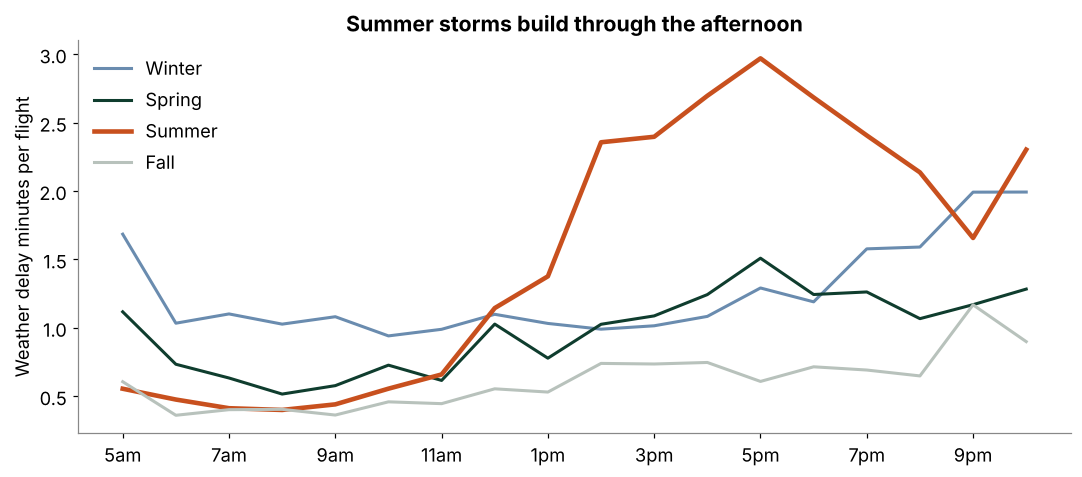

Summer weather minutes/flight: morning 0.44 -> evening 2.70; winter 1.12 -> 1.34


In [21]:
import gc
for v in ['f', 'fl', 't', 'train', 'test', 'w', 'dl', 'hv', 'grp', 'wide', 'rc', 'reg', 'd', 'g']:   # free memory from earlier cells
    globals().pop(v, None)
df.drop(columns=['CARRIER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'DEP_DELAY', 'DISTANCE', 'leg', 'TAIL_NUM'], inplace=True, errors='ignore')
gc.collect()
df['wx_cancel'] = df.cancelled & (df.CANCELLATION_CODE.astype(str) == 'B')
df['wx_min'] = df.WEATHER_DELAY.fillna(0)
df['day'] = df.MONTH.astype(int) * 100 + df.DAY_OF_MONTH.astype(int)
R['wx_cancel_pct'] = df.wx_cancel.mean() * 100

# 1) Summer storms build through the afternoon? Weather delay minutes per flight by hour, per season
fw = df[df.flew & df.hour.between(5, 22)]
wh = fw.groupby(['season', 'hour'], observed=True).wx_min.mean().unstack(0)[['Winter', 'Spring', 'Summer', 'Fall']]
R['wx_min_summer_morning'] = float(fw[(fw.season == 'Summer') & (fw.band == 'Morning')].wx_min.mean())
R['wx_min_summer_evening'] = float(fw[(fw.season == 'Summer') & (fw.band == 'Evening')].wx_min.mean())
R['wx_min_winter_morning'] = float(fw[(fw.season == 'Winter') & (fw.band == 'Morning')].wx_min.mean())
R['wx_min_winter_evening'] = float(fw[(fw.season == 'Winter') & (fw.band == 'Evening')].wx_min.mean())
fig, ax = plt.subplots(figsize=(10, 4.5))
for c, col in zip(wh.columns, ['#6A8CAF', GREEN, ORANGE, GREY]):
    ax.plot(wh.index, wh[c], lw=3 if c == 'Summer' else 2, color=col, label=c)
ax.set_xticks(range(5, 23, 2)); ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in range(5, 23, 2)])
ax.set_ylabel('Weather delay minutes per flight'); ax.set_title('Summer storms build through the afternoon'); ax.legend(frameon=False)
save('10_weather_by_hour')
print(f"Summer weather minutes/flight: morning {R['wx_min_summer_morning']:.2f} -> evening {R['wx_min_summer_evening']:.2f}; "
      f"winter {R['wx_min_winter_morning']:.2f} -> {R['wx_min_winter_evening']:.2f}")

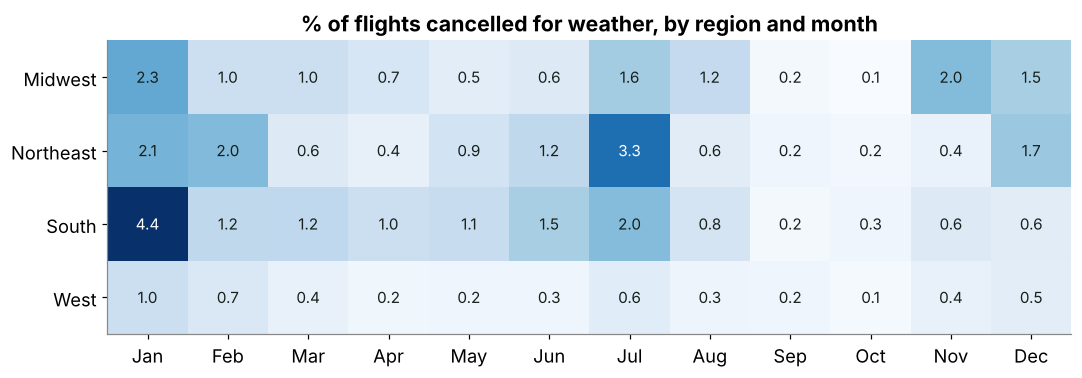

MONTH,1,2,3,4,5,6,7,8,9,10,11,12
region,,,,,,,,,,,,
Midwest,2.33,1.00,1.00,0.75,0.51,0.64,1.61,1.15,0.16,0.07,1.97,1.54
Northeast,2.12,1.98,0.63,0.41,0.86,1.24,3.34,0.55,0.25,0.18,0.37,1.70
South,4.37,1.25,1.23,1.00,1.10,1.54,1.95,0.82,0.17,0.26,0.63,0.55
West,1.01,0.69,0.40,0.23,0.25,0.27,0.58,0.28,0.24,0.12,0.38,0.52


In [22]:
# 2) Where and when weather cancels flights: region x month
reg = df[df.region != 'Territories']
wc = reg.groupby(['region', 'MONTH']).wx_cancel.mean().unstack() * 100
R['wx_cancel_region_month'] = wc.round(2).to_dict(orient='index')
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(wc.values, cmap='Blues', aspect='auto')
for i in range(wc.shape[0]):
    for j in range(12):
        ax.text(j, i, f'{wc.values[i, j]:.1f}', ha='center', va='center', fontsize=10, color='white' if wc.values[i, j] > wc.values.max() * 0.6 else INK)
ax.set_xticks(range(12)); ax.set_xticklabels(M); ax.set_yticks(range(len(wc))); ax.set_yticklabels(wc.index)
ax.set_title('% of flights cancelled for weather, by region and month')
save('11_wx_cancel_region_month')
wc.round(2)

In [23]:
# 3) Storm days: a few bad days do most of the damage
rd = df.groupby(['region', 'day'], observed=True).agg(flights=('wx_cancel', 'size'), wx_cancel=('wx_cancel', 'sum'), wx_min=('wx_min', 'sum'))
rd['wx_cancel_pct'] = rd.wx_cancel / rd.flights * 100
rd = rd[rd.flights >= 300]
rd['storm_day'] = rd.wx_cancel_pct >= 3          # 3%+ of a region's flights cancelled for weather that day
R['storm_days'] = int(rd.storm_day.sum()); R['region_days'] = len(rd)
R['storm_share_of_wx_cancels'] = float(rd[rd.storm_day].wx_cancel.sum() / rd.wx_cancel.sum() * 100)
R['storm_share_of_days'] = float(rd.storm_day.mean() * 100)
top = rd.sort_values('wx_cancel', ascending=False).head(12).reset_index()
top['date'] = pd.to_datetime('2025-' + (top.day // 100).astype(str) + '-' + (top.day % 100).astype(str)).dt.strftime('%b %d')
R['top_storm_days'] = top[['region', 'date', 'flights', 'wx_cancel', 'wx_cancel_pct']].round(1).to_dict(orient='records')
sd = rd[rd.storm_day].reset_index()
sd['season'] = (sd.day // 100).map({12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
                                     6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Fall', 10: 'Fall', 11: 'Fall'})
R['storm_days_by_region_season'] = sd.groupby(['region', 'season']).size().unstack(fill_value=0).to_dict(orient='index')
print(f"{R['storm_days']} storm region-days out of {R['region_days']:,} ({R['storm_share_of_days']:.1f}%) caused "
      f"{R['storm_share_of_wx_cancels']:.0f}% of all weather cancellations")
display(top[['region', 'date', 'flights', 'wx_cancel', 'wx_cancel_pct']].round(1))
pd.DataFrame(R['storm_days_by_region_season']).T

123 storm region-days out of 1,460 (8.4%) caused 59% of all weather cancellations


,region,date,flights,wx_cancel,wx_cancel_pct
0,South,Jan 10,6460,1910,29.6
1,South,Jan 09,6587,1300,19.7
2,South,Jan 21,6216,1221,19.6
3,South,Jan 22,6251,1060,17.0
4,Midwest,Nov 29,3077,1030,33.5
5,South,Jan 06,6738,991,14.7
6,South,Apr 30,7114,608,8.5
7,South,Mar 04,6446,584,9.1
8,South,Jan 05,7076,518,7.3
9,South,May 06,7051,508,7.2


,Fall,Spring,Summer,Winter
Midwest,3,4,9,14
Northeast,3,4,16,18
South,3,12,17,15
West,1,0,0,4


**What were the worst storm days?** Matched to news and NOAA reports (each one opened and checked):

| Storm day(s) in the data | Region | What happened | Source |
|---|---|---|---|
| Jan 9–10 | South | Winter Storm Cora: biggest snowfall in years in Atlanta, Dallas, Charlotte; 2,000+ US flights cancelled Jan 10 | [Weather Network](https://www.theweathernetwork.com/en/news/weather/severe/thousands-of-flights-cancelled-as-biggest-snowfall-in-years-hits-southern-us-atlanta-dallas-charlotte) |
| Jan 21–22 | South | Gulf Coast blizzard: record snow in New Orleans, Pensacola, Mobile; most Houston and New Orleans flights cancelled | [Wikipedia](https://en.wikipedia.org/wiki/2025_Gulf_Coast_blizzard) |
| Jul 14 | Northeast | Slow-moving thunderstorms and flash floods; Newark cancelled 13% of flights | [PropertyCasualty360](https://www.propertycasualty360.com/2025/07/15/flight-cancellations-surge-after-new-york-struck-by-storm) |
| Jul 29–30 | Hawaii | Tsunami warning after the M8.8 Kamchatka quake; Hilo flights suspended | [Aviation A2Z](https://aviationa2z.com/index.php/2025/07/30/hawaiian-airlines-cancels-flights-after-russia-earthquake/) |
| Nov 29 | Midwest | Post-Thanksgiving snowstorm: O'Hare record 8.4 in of November snow | [PBS NewsHour](https://www.pbs.org/newshour/nation/winter-storm-snarls-flights-for-post-thanksgiving-travelers-in-chicago) |

**Hurricanes:** no hurricane made landfall in the continental US in 2025, the first such year since 2015
([NOAA NESDIS](https://www.nesdis.noaa.gov/news/2025-atlantic-hurricane-season-marked-high-powered-storms-no-us-landfalling-hurricanes)).
So 2025 under-states hurricane risk, which is why the Aug–Oct numbers below look calm.

**El Niño / La Niña:** 2025 had no El Niño. NOAA reported La Niña in January, ENSO-neutral from March, and La Niña again by fall
([Jan](https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso_disc_jan2025/ensodisc.pdf),
[Apr](https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso_disc_apr2025/ensodisc.shtml),
[Nov](https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso_disc_nov2025/ensodisc.shtml) discussions).
With one year we can't separate a climate phase from normal variation, so we make no El Niño claim.

**Tides:** tides themselves don't cancel flights in this data; their risk comes through storm surge (hurricanes) and tsunamis like July 29.

In [24]:
# 4) Does flying early help on storm days?
rcode = {r: i for i, r in enumerate(df.region.cat.categories)}
storm_keys = [rcode[r] * 10000 + d for r, d in rd[rd.storm_day].index]
df['on_storm_day'] = (df.region.cat.codes.astype('int32') * 10000 + df.day.astype('int32')).isin(storm_keys)
s = df[df.on_storm_day & df.band.isin(['Morning', 'Evening'])]
sb = s.groupby('band', observed=True).agg(cancel=('cancelled', 'mean'), severe=('severe', 'mean'))
R['storm_morning_cancel'] = float(sb.loc['Morning', 'cancel'] * 100); R['storm_evening_cancel'] = float(sb.loc['Evening', 'cancel'] * 100)
R['storm_morning_severe'] = float(sb.loc['Morning', 'severe'] * 100); R['storm_evening_severe'] = float(sb.loc['Evening', 'severe'] * 100)
R['normal_severe'] = float(df[~df.on_storm_day].severe.mean() * 100)
R['storm_severe_all'] = float(df[df.on_storm_day].severe.mean() * 100)
print(f"On storm days: lost-day risk {R['storm_severe_all']:.1f}% (normal days {R['normal_severe']:.1f}%). "
      f"Morning {R['storm_morning_severe']:.1f}% vs evening {R['storm_evening_severe']:.1f}%; "
      f"cancelled morning {R['storm_morning_cancel']:.1f}% vs evening {R['storm_evening_cancel']:.1f}%")

On storm days: lost-day risk 24.6% (normal days 8.4%). Morning 13.8% vs evening 36.2%; cancelled morning 5.8% vs evening 11.2%


In [25]:
# 5) Most weather-exposed airports (10k+ flights): winter vs summer weather-cancel rate
ap = df.groupby(['ORIGIN', 'season'], observed=True).agg(n=('wx_cancel', 'size'), wc=('wx_cancel', 'mean'), st=('ORIGIN_STATE_ABR', 'first')).reset_index()
big = df.ORIGIN.value_counts(); big = big[big >= 10000].index
ap = ap[ap.ORIGIN.isin(big)]
R['airports_winter'] = ap[ap.season == 'Winter'].nlargest(8, 'wc').assign(wc=lambda d: (d.wc * 100).round(2))[['ORIGIN', 'st', 'wc']].to_dict(orient='records')
R['airports_summer'] = ap[ap.season == 'Summer'].nlargest(8, 'wc').assign(wc=lambda d: (d.wc * 100).round(2))[['ORIGIN', 'st', 'wc']].to_dict(orient='records')
R['airports_fall'] = ap[ap.season == 'Fall'].nlargest(8, 'wc').assign(wc=lambda d: (d.wc * 100).round(2))[['ORIGIN', 'st', 'wc']].to_dict(orient='records')
# Hurricane-belt check: Florida + Gulf states, Aug-Oct vs rest of year
gulf = df.ORIGIN_STATE_ABR.astype(str).isin(['FL', 'LA', 'MS', 'AL', 'TX', 'SC', 'GA', 'NC'])
hs = df.MONTH.between(8, 10)
R['gulf_wx_cancel_hurricane_season'] = float(df[gulf & hs].wx_cancel.mean() * 100)
R['gulf_wx_cancel_rest'] = float(df[gulf & ~hs].wx_cancel.mean() * 100)
# Typhoon check: Pacific islands and Hawaii
pac = df.ORIGIN_STATE_ABR.astype(str).isin(['TT', 'HI', 'GU', 'MP'])
R['pacific_flights'] = int(pac.sum())
R['pacific_states'] = df[pac].ORIGIN_STATE_ABR.astype(str).value_counts().to_dict()
pm = df[pac].groupby('MONTH').wx_cancel.mean() * 100
R['pacific_wx_cancel_by_month'] = pm.round(3).to_dict()
print('Winter:', R['airports_winter']); print('Summer:', R['airports_summer']); print('Fall:', R['airports_fall'])
print(f"Gulf/Southeast weather cancels: Aug-Oct {R['gulf_wx_cancel_hurricane_season']:.2f}% vs rest {R['gulf_wx_cancel_rest']:.2f}%")
print('Pacific:', R['pacific_states'], R['pacific_wx_cancel_by_month'])

Winter: [{'ORIGIN': 'PNS', 'st': 'FL', 'wc': 4.33}, {'ORIGIN': 'SAV', 'st': 'GA', 'wc': 4.22}, {'ORIGIN': 'DCA', 'st': 'VA', 'wc': 4.1}, {'ORIGIN': 'CHS', 'st': 'SC', 'wc': 3.76}, {'ORIGIN': 'MSY', 'st': 'LA', 'wc': 3.53}, {'ORIGIN': 'HPN', 'st': 'NY', 'wc': 3.48}, {'ORIGIN': 'ICT', 'st': 'KS', 'wc': 3.17}, {'ORIGIN': 'MCI', 'st': 'MO', 'wc': 2.99}]
Summer: [{'ORIGIN': 'DCA', 'st': 'VA', 'wc': 3.96}, {'ORIGIN': 'PHL', 'st': 'PA', 'wc': 2.69}, {'ORIGIN': 'LGA', 'st': 'NY', 'wc': 2.6}, {'ORIGIN': 'DFW', 'st': 'TX', 'wc': 2.48}, {'ORIGIN': 'PVD', 'st': 'RI', 'wc': 2.03}, {'ORIGIN': 'ICT', 'st': 'KS', 'wc': 1.94}, {'ORIGIN': 'CLE', 'st': 'OH', 'wc': 1.92}, {'ORIGIN': 'GSO', 'st': 'NC', 'wc': 1.91}]
Fall: [{'ORIGIN': 'DSM', 'st': 'IA', 'wc': 1.36}, {'ORIGIN': 'DFW', 'st': 'TX', 'wc': 1.17}, {'ORIGIN': 'ORD', 'st': 'IL', 'wc': 1.07}, {'ORIGIN': 'MDW', 'st': 'IL', 'wc': 1.06}, {'ORIGIN': 'MKE', 'st': 'WI', 'wc': 0.8}, {'ORIGIN': 'MSN', 'st': 'WI', 'wc': 0.79}, {'ORIGIN': 'GRR', 'st': 'MI', 'w

## 11. Scorecard

In [26]:
score = pd.DataFrame([
    ['1 Fly early', 'Gap survives same route + airline', f"{R['raw_gap_pp']:.1f} -> {R['matched_gap_pp']:.1f} pts", R['test1a_pass']],
    ['1 Fly early', 'Late-aircraft delay snowballs', f"{R['la_min_morning']:.1f} -> {R['la_min_evening']:.1f} min/flight", R['test1b_pass']],
    ['2 Night before', 'Peak-month evening risk >= 1.5x average', f"{R['severe_peak_evening']:.1f}% vs {R['severe_all']:.1f}%", R['test2_pass']],
    ['3 Buffer', 'Coverage 87-93% on unseen days', f"{R['buffer_cov_mean']:.1f}%", R['test3_pass']],
    ['4 Reliable carrier', 'Winner holds on >= 70% of routes', f"{R['carrier_hold_pct']:.0f}%", R['test4_pass']],
], columns=['Rule', 'Kill test', 'Result', 'Survives'])
score

,Rule,Kill test,Result,Survives
0,1 Fly early,Gap survives same route + airline,19.2 -> 19.8 pts,True
1,1 Fly early,Late-aircraft delay snowballs,1.8 -> 11.1 min/flight,True
2,2 Night before,Peak-month evening risk >= 1.5x average,21.6% vs 9.7%,True
3,3 Buffer,Coverage 87-93% on unseen days,90.4%,True
4,4 Reliable carrier,Winner holds on >= 70% of routes,77%,True


## 12. Simplified charts for the deck
Same numbers as above, drawn with one idea per chart so anyone in the room can read them in five seconds.

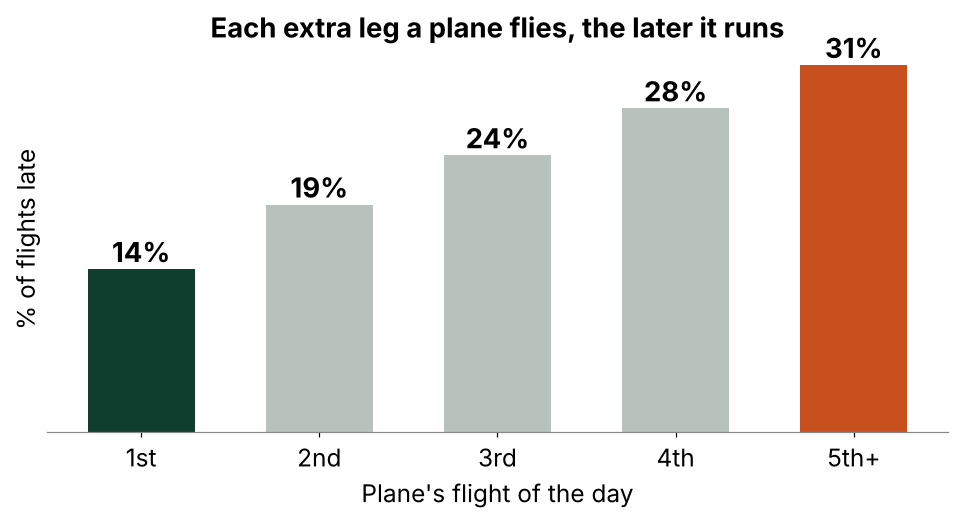

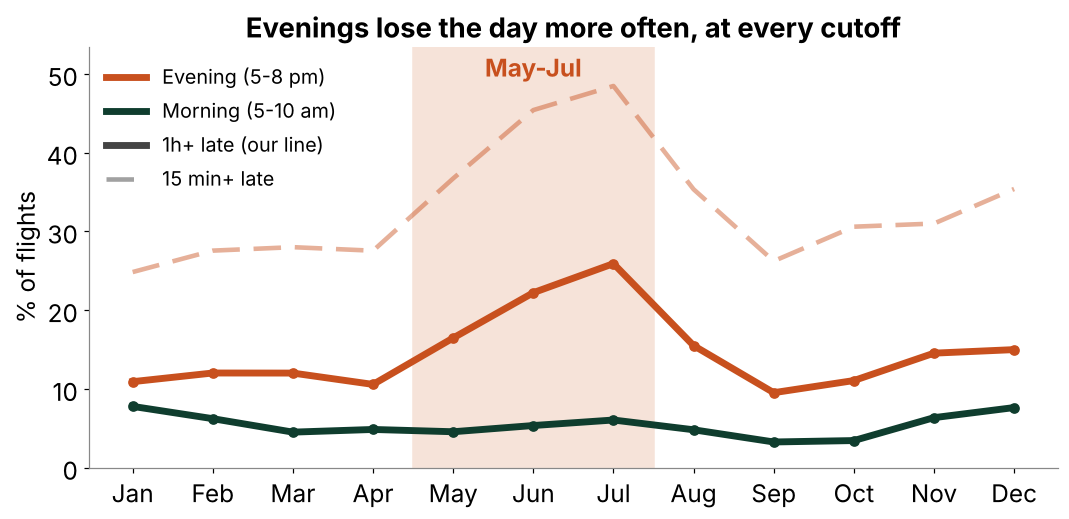

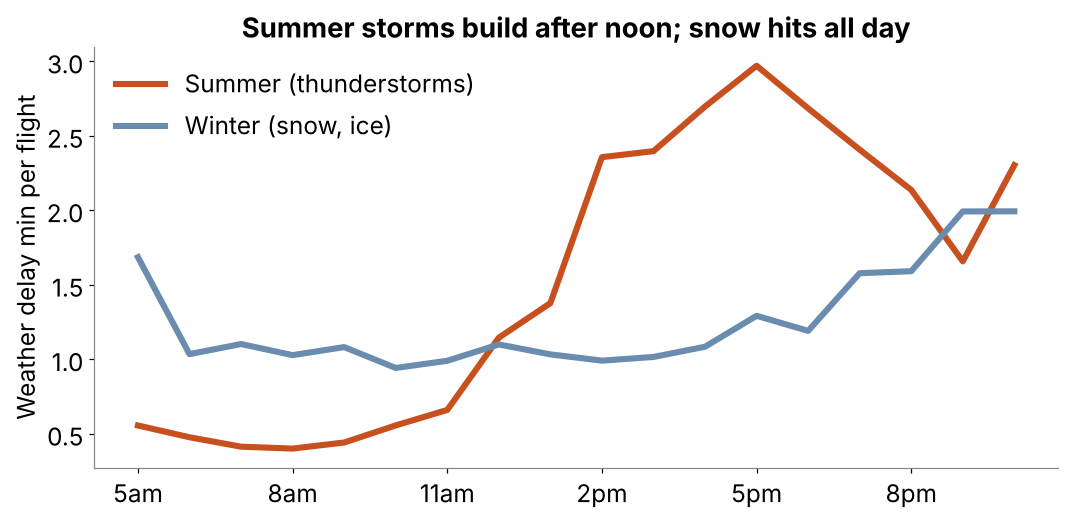

,Early (5-10am),Evening (5-8pm)
Winter,45,90
Spring,30,90
Summer,30,135
Fall,30,75


In [27]:
plt.rcParams.update({'font.size': 16, 'axes.titlesize': 18})
# A) The snowball, simply: late rate by which leg of the plane's day it is
lg = pd.Series(R['late_by_leg'])
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(lg.index, lg.values, color=[GREEN, GREY, GREY, GREY, ORANGE], width=0.6)
for i, v in enumerate(lg.values): ax.text(i, v + 0.6, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=18)
ax.set_ylabel('% of flights late'); ax.set_xlabel("Plane's flight of the day"); ax.set_yticks([])
ax.spines['left'].set_visible(False); ax.set_title('Each extra leg a plane flies, the later it runs')
save('s1_leg_of_day')

# B) Lost-day risk: solid = 1h+ (our line); translucent dashed = 15 min+ and 2h+ for comparison
from matplotlib.lines import Line2D
ev = pd.Series(R['severe_by_month_evening']).astype(float); mo = pd.Series(R['severe_by_month_morning']).astype(float)
x = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(4.5, 7.5, color='#F6E3D9')
for tag, ls in [('15', (0, (6, 3)))]:
    ax.plot(x, pd.Series(R[f'cut{tag}_by_month_evening']).astype(float).values, color=ORANGE, lw=3, ls=ls, alpha=0.45)
ax.plot(x, ev.values, color=ORANGE, lw=4.5, marker='o')
ax.plot(x, mo.values, color=GREEN, lw=4.5, marker='o')
top = max(pd.Series(R['cut15_by_month_evening']).astype(float).max(), ev.max())
ax.text(6, top + 1.2, 'May-Jul', ha='center', color=ORANGE, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(M); ax.set_ylabel('% of flights'); ax.set_ylim(0, top + 5)
h = [Line2D([0], [0], color=ORANGE, lw=4.5, label='Evening (5-8 pm)'), Line2D([0], [0], color=GREEN, lw=4.5, label='Morning (5-10 am)'),
     Line2D([0], [0], color='#444', lw=4.5, label='1h+ late (our line)'),
     Line2D([0], [0], color='#444', lw=3, ls=(0, (6, 3)), alpha=0.5, label='15 min+ late')]
ax.legend(handles=h, frameon=False, loc='upper left', fontsize=13, ncol=1)
ax.set_title('Evenings lose the day more often, at every cutoff'); 
save('s2_lost_day_lines')

# C) Weather: summer storms build after noon, winter snow hits all day
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wh.index, wh['Summer'], color=ORANGE, lw=4, label='Summer (thunderstorms)')
ax.plot(wh.index, wh['Winter'], color='#6A8CAF', lw=4, label='Winter (snow, ice)')
ax.set_xticks(range(5, 23, 3)); ax.set_xticklabels([f'{h % 12 or 12}{"am" if h < 12 else "pm"}' for h in range(5, 23, 3)])
ax.set_ylabel('Weather delay min per flight'); ax.legend(frameon=False, loc='upper left')
ax.set_title('Summer storms build after noon; snow hits all day')
save('s3_weather_summer_winter')

# D) Buffer card, simplified: median buffer by season, morning vs evening
card = pd.DataFrame(R['buffer_card'])
season_of = {'Dec': 'Winter', 'Jan': 'Winter', 'Feb': 'Winter', 'Mar': 'Spring', 'Apr': 'Spring', 'May': 'Spring',
             'Jun': 'Summer', 'Jul': 'Summer', 'Aug': 'Summer', 'Sep': 'Fall', 'Oct': 'Fall', 'Nov': 'Fall'}
simple = card.groupby(card.index.map(season_of))[['Early (5-10am)', 'Evening (5-8pm)']].max().loc[['Winter', 'Spring', 'Summer', 'Fall']]
R['buffer_simple'] = simple.to_dict(orient='index')
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 14})
simple

In [28]:
json.dump(R, open('results/kill_tests_results.json', 'w'), indent=1, default=float)
print('saved results/kill_tests_results.json')

saved results.json


## 12. Limits we state up front
- No fares, itineraries, connections or trip purpose in BTS data, so fare trade-offs are the client's to price.
- One year (2025). Results are patterns, not proof of cause; the same-route test is the closest this data gets.
- $60/hour, 4 hours per cancellation and the 3-hour cap are assumptions; section 10 shows the ranking holds across $30–$150.